# Data format vs. token usage: exploratory analysis

**Question:** when a prompt contains a dataset, does the **format of that data** (CSV, XML, or prose) change how many tokens an LLM uses to write Python code for it?

- **Controls:** same model, temperature, and system prompt on every call.
- **Data:** 20-row samples from the [Oracle's Elixir](https://oracleselixir.com) 2025 LoL esports match data.

In [1]:
import ast
import html
import json
import re
import sys
import textwrap
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import HTML, Markdown

sys.path.insert(0, "../src")
from evaluate import extract_code

SEED = 42
RESULTS_CSV = "../data/results.csv"
MODEL = "qwen2.5-coder:7b"

DATA_FORMATS = ["csv", "xml", "prose"]
DATA_COLORS = {"csv": "#008300", "xml": "#4a3aa7", "prose": "#e87ba4"}
DATA_MARKERS = {"csv": "o", "xml": "s", "prose": "D"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

responses = pd.read_csv(RESULTS_CSV)
responses = responses[responses["model"] == MODEL].copy()
responses["total_tokens"] = responses["input_tokens"] + responses["output_tokens"]

is_parse = responses["task_id"].str.endswith("_parse")
copy_rows = responses[~is_parse].copy()    # sections 1-4: the code contains the data
parse_rows = responses[is_parse].copy()    # sections 5-7: the code receives the data as text
valid = copy_rows[copy_rows["passed_all"]].copy()   # code runs and contains all the data
print(f"{len(copy_rows)} copy rows ({len(valid)} valid), {len(parse_rows)} parse rows")
responses.head()

180 copy rows (158 valid), 180 parse rows


,task_id,format,data_format,run,model,input_tokens,output_tokens,tests_passed,tests_total,passed_all,stop_reason,timestamp,total_tokens
0,t12_gold_lead,informal,xml,1,qwen2.5-coder:7b,1158,1010,2,2,True,stop,2026-10-14T17:20:11+00:00,2168
1,t11_side_winrate,informal,csv,1,qwen2.5-coder:7b,517,714,2,2,True,stop,2026-10-14T17:20:23+00:00,1231
2,t16_support_vision,structured,csv,1,qwen2.5-coder:7b,584,1178,2,2,True,stop,2026-10-14T17:20:42+00:00,1762
3,t11_side_winrate,structured,csv,1,qwen2.5-coder:7b,532,1016,2,2,True,stop,2026-10-14T17:20:58+00:00,1548
4,t16_support_vision,structured,xml,1,qwen2.5-coder:7b,1366,1140,2,2,True,stop,2026-10-14T17:21:17+00:00,2506


In [2]:
TASKS_DIR = Path("../tasks")
TASK_IDS = sorted(p.name for p in TASKS_DIR.glob("t*") if p.is_dir() and not p.name.endswith("_parse"))

def read_task_file(task_id, name):
    return (TASKS_DIR / task_id / name).read_text(encoding="utf-8")

print("Tasks:", ", ".join(TASK_IDS))

Tasks: t11_side_winrate, t12_gold_lead, t13_objectives, t14_mid_kda, t15_jungle_picks, t16_support_vision


In [3]:
EXAMPLE_DATA_TASK = "t11_side_winrate"

def preview(text, data_format, n=4):
    """The first n rows of a data block (prose rows are sentences, so cut by characters instead)."""
    if data_format == "prose":
        return textwrap.fill(text[:420], 60) + " ..."
    lines = text.splitlines()
    return "\n".join(lines[:n + 1]) + "\n..."   # +1 for the CSV header / opening <rows> tag

columns = "".join(
    f'<td style="vertical-align:top; padding:0 12px"><b>data_{d}.txt</b>'
    f'<pre style="white-space:pre-wrap">{html.escape(preview(read_task_file(EXAMPLE_DATA_TASK, f"data_{d}.txt"), d))}</pre></td>'
    for d in DATA_FORMATS
)
display(Markdown(f"#### `{EXAMPLE_DATA_TASK}`: first rows in each data format"))
display(HTML(f"<table><tr>{columns}</tr></table>"))

#### `t11_side_winrate`: first rows in each data format

"data_csv.txtgame,team,side,result,game_minutes G01,DN Freecs,blue,loss,34.1 G01,Dplus KIA,red,win,34.1 G02,BNK FEARX,blue,loss,40.1 G02,Gen.G,red,win,40.1 ...",data_xml.txt<rows> <row><game>G01</game><team>DN Freecs</team><side>blue</side><result>loss</result><game_minutes>34.1</game_minutes></row> <row><game>G01</game><team>Dplus KIA</team><side>red</side><result>win</result><game_minutes>34.1</game_minutes></row> <row><game>G02</game><team>BNK FEARX</team><side>blue</side><result>loss</result><game_minutes>40.1</game_minutes></row> <row><game>G02</game><team>Gen.G</team><side>red</side><result>win</result><game_minutes>40.1</game_minutes></row> ...,"data_prose.txtIn game G01, DN Freecs played on the blue side and lost; the game lasted 34.1 minutes. In game G01, Dplus KIA played on the red side and won; the game lasted 34.1 minutes. In game G02, BNK FEARX played on the blue side and lost; the game lasted 40.1 minutes. In game G02, Gen.G played on the red side and won; the game lasted 40.1 minutes. In game G03, Dplus KIA played on the blue side and won; the game lasted 27.5 min ..."


In [4]:
data_rows = []
for task_id in TASK_IDS:
    row = {"task_id": task_id, "rows": len(json.loads(read_task_file(task_id, "sample.json")))}
    for d in DATA_FORMATS:
        row[f"{d} chars"] = len(read_task_file(task_id, f"data_{d}.txt"))
    data_rows.append(row)
data_table = pd.DataFrame(data_rows).set_index("task_id")

input_by_format = copy_rows.groupby(["task_id", "data_format"])["input_tokens"].mean().unstack()
for d in DATA_FORMATS:
    data_table[f"{d} input tokens"] = input_by_format[d].round(0)
data_table

,rows,csv chars,xml chars,prose chars,csv input tokens,xml input tokens,prose input tokens
task_id,,,,,,,
t11_side_winrate,20,627,2487,1752,524.0,1062.0,722.0
t12_gold_lead,20,617,2477,2062,515.0,1168.0,825.0
t13_objectives,20,794,3397,2412,558.0,1417.0,855.0
t14_mid_kda,20,801,3287,1812,574.0,1356.0,716.0
t15_jungle_picks,20,459,2084,1209,380.0,894.0,498.0
t16_support_vision,20,803,3639,2064,572.0,1354.0,787.0


## 1. Tokens by data format

In [5]:
valid.groupby("data_format")[["input_tokens", "output_tokens", "total_tokens"]].agg(["mean", "median"]).round(0).loc[DATA_FORMATS]

input_tokens         output_tokens         total_tokens        
                    mean  median          mean  median         mean  median
data_format                                                                
csv                529.0   546.0        1043.0  1114.0       1572.0  1647.0
xml               1229.0  1342.0        1116.0  1140.0       2345.0  2488.0
prose              723.0   729.0         836.0   786.0       1558.0  1537.0

## 2. Output tokens by data format

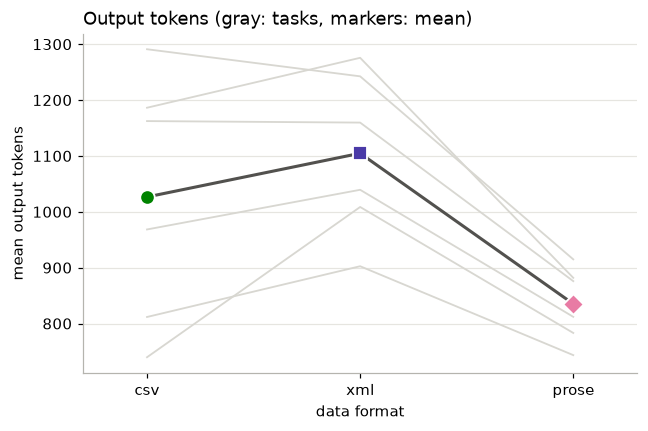

In [6]:
per_task = valid.groupby(["task_id", "data_format"])["output_tokens"].mean().unstack()[DATA_FORMATS]
x = np.arange(len(DATA_FORMATS))

fig, ax = plt.subplots(figsize=(6.5, 4))
for task_id, row in per_task.iterrows():
    ax.plot(x, row.values, color="#d8d7d1", linewidth=1.2, zorder=1)
ax.plot(x, per_task.mean().values, color="#52514e", linewidth=2, zorder=2)
for i, d in enumerate(DATA_FORMATS):
    ax.scatter(i, per_task[d].mean(), s=90, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=3,
               edgecolor="white", linewidth=1.2)
ax.set_xticks(x, DATA_FORMATS)
ax.set_xlim(-0.3, len(DATA_FORMATS) - 0.7)
ax.set_xlabel("data format")
ax.set_ylabel("mean output tokens")
ax.set_title("Output tokens (gray: tasks, markers: mean)", loc="left")
ax.grid(axis="x", visible=False)
plt.show()

## 3. Output vs input tokens

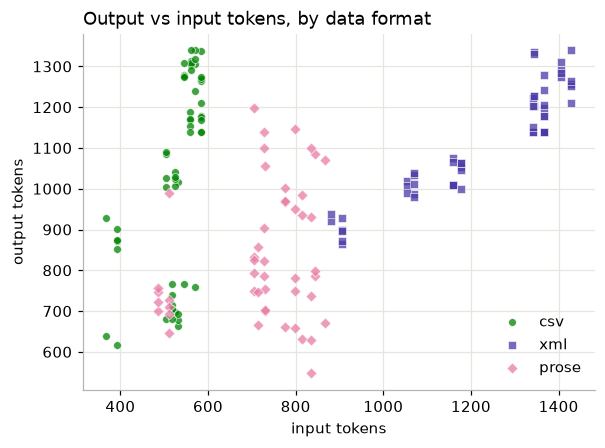

,mean output / input
data_format,
csv,1.97
xml,0.92
prose,1.16


In [7]:
valid["output_per_input"] = valid["output_tokens"] / valid["input_tokens"]

fig, ax = plt.subplots(figsize=(6, 4.2))
for d in DATA_FORMATS:
    sub_rows = valid[valid["data_format"] == d]
    ax.scatter(sub_rows["input_tokens"], sub_rows["output_tokens"], s=26, alpha=0.75, color=DATA_COLORS[d],
               marker=DATA_MARKERS[d], edgecolor="white", linewidth=0.5, label=d)
ax.set_xlabel("input tokens")
ax.set_ylabel("output tokens")
ax.set_title("Output vs input tokens, by data format", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

ratio = valid.groupby(["task_id", "data_format"])["output_per_input"].mean().unstack()[DATA_FORMATS]
ratio.mean().round(2).to_frame("mean output / input")

## 4. How the model stored the data

Reads the saved responses in `data/raw/` (local only).

In [8]:
def storage_style(code_text):
    """How the model wrote the 20 rows into its code: dicts with a key per value, or bare tuples/lists."""
    dict_rows = code_text.count('{"') + code_text.count("{'")          # {"team": ..., "side": ...}
    tuple_rows = sum(line.strip()[:2] in ('("', "('", '["', "['")      # ("DN Freecs", "blue", ...)
                     for line in code_text.splitlines())
    if dict_rows >= 15:
        return "dicts with keys"
    if tuple_rows >= 15:
        return "tuples/lists"
    return "other"

safe_model = MODEL.replace(":", "-").replace("/", "-")
style_rows = []
for path in Path("../data/raw").glob(f"*__{safe_model}.txt"):
    task_id, fmt, data_format, run, _ = path.stem.split("__")
    if data_format not in DATA_FORMATS:
        continue
    code_text = extract_code(path.read_text(encoding="utf-8"))
    style_rows.append({"task_id": task_id, "format": fmt, "data_format": data_format,
                       "run": int(run.removeprefix("run")), "style": storage_style(code_text)})
styles = pd.DataFrame(style_rows).merge(valid, on=["task_id", "format", "data_format", "run"])

display(pd.crosstab(styles["data_format"], styles["style"]).loc[DATA_FORMATS])
display(styles.groupby("style")["output_tokens"].agg(["count", "mean"]).round(0))
display(styles.groupby(["data_format", "style"])["output_tokens"].agg(["count", "mean"]).round(0).loc[DATA_FORMATS])

style,dicts with keys,other,tuples/lists
data_format,,,
csv,42,0,14
xml,54,0,0
prose,17,2,29


,count,mean
style,,
dicts with keys,113,1118.0
other,2,606.0
tuples/lists,43,726.0


count    mean
data_format style                         
csv         dicts with keys     42  1158.0
            tuples/lists        14   700.0
xml         dicts with keys     54  1116.0
prose       dicts with keys     17  1028.0
            other                2   606.0
            tuples/lists        29   739.0

## 5. Parse version: tokens by data format

The code receives the data as text (`q1(text)`) instead of containing it.

In [9]:
def prompt_names(task_id):
    for node in ast.parse((TASKS_DIR / task_id / "test_solution.py").read_text(encoding="utf-8")).body:
        if isinstance(node, ast.Assign) and node.targets[0].id == "PROMPT_NAMES":
            return ast.literal_eval(node.value)

def normalize(text):
    return unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower()

def saved_code(r):
    path = Path("../data/raw") / f"{r.task_id}__{r.format}__{r.data_format}__run{r.run}__{safe_model}.txt"
    return extract_code(path.read_text(encoding="utf-8"))

parse_rows["code_text"] = [saved_code(r) for r in parse_rows.itertuples()]
parse_rows["copied"] = [sum(normalize(n) in normalize(code_text) for n in prompt_names(task_id)) > 2
                        for task_id, code_text in zip(parse_rows["task_id"], parse_rows["code_text"])]
attempts = parse_rows[~parse_rows["copied"]].copy()   # responses that didn't copy the data
print(f"{len(attempts)} of {len(parse_rows)} parse responses didn't copy the data")
attempts.groupby("data_format")[["input_tokens", "output_tokens", "total_tokens"]].agg(["mean", "median"]).round(0).loc[DATA_FORMATS]

176 of 180 parse responses didn't copy the data


input_tokens         output_tokens        total_tokens        
                    mean  median          mean median         mean  median
data_format                                                               
csv                543.0   565.0         240.0  237.0        783.0   789.0
xml               1231.0  1282.0         326.0  318.0       1557.0  1594.0
prose              755.0   794.0         328.0  318.0       1083.0  1103.0

## 6. Copy vs parse: output tokens

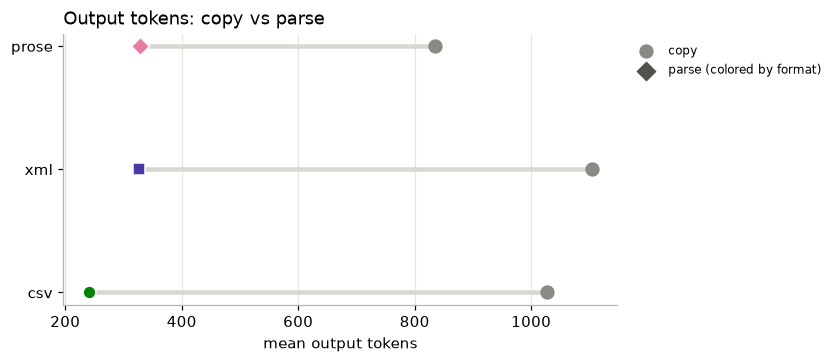

,copy,parse,parse / copy
data_format,,,
csv,1027.0,240.0,0.23
xml,1105.0,326.0,0.30
prose,835.0,328.0,0.39


In [10]:
copy_means = valid.groupby(["task_id", "data_format"])["output_tokens"].mean()
twin_ids = attempts["task_id"].str.removesuffix("_parse").str.replace("t2", "t1", n=1)
parse_means = attempts.assign(task_id=twin_ids).groupby(["task_id", "data_format"])["output_tokens"].mean()
copy_vs_parse = pd.DataFrame({"copy": copy_means, "parse": parse_means}).dropna().groupby("data_format").mean().loc[DATA_FORMATS].round(0)
copy_vs_parse["parse / copy"] = (copy_vs_parse["parse"] / copy_vs_parse["copy"]).round(2)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
y = np.arange(len(DATA_FORMATS))
ax.hlines(y, copy_vs_parse["parse"], copy_vs_parse["copy"], color="#d8d7d1", linewidth=3, zorder=1)
ax.scatter(copy_vs_parse["copy"], y, s=70, color="#8a8984", zorder=2, label="copy")
for i, d in enumerate(DATA_FORMATS):
    ax.scatter(copy_vs_parse.loc[d, "parse"], i, s=70, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=3,
               edgecolor="white", linewidth=1)
ax.scatter([], [], s=70, color="#52514e", marker="D", label="parse (colored by format)")
ax.set_yticks(y, DATA_FORMATS)
ax.set_xlabel("mean output tokens")
ax.set_title("Output tokens: copy vs parse", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.show()
copy_vs_parse

## 7. Parse version: did the code run on new data?

In [11]:
parse_rows["code ran on new data"] = parse_rows["passed_all"] | ((parse_rows["tests_passed"] == 1) & parse_rows["copied"])
parse_rows["uses pandas"] = parse_rows["code_text"].str.contains("import pandas")
parse_rows["uses removed pandas call"] = parse_rows["code_text"].str.contains("compat.StringIO")
parse_rows.groupby("data_format")[["code ran on new data", "uses pandas", "uses removed pandas call"]].mean().round(2).loc[DATA_FORMATS]

,code ran on new data,uses pandas,uses removed pandas call
data_format,,,
csv,0.52,0.32,0.3
xml,0.82,0.00,0.0
prose,0.52,0.00,0.0


## Summary

- XML: about 2.3× the input tokens of CSV, about 50% more total tokens.
- Prose: more input than CSV, least output; CSV and prose about even in total.
- Output is driven by storage style: dicts with keys ≈ 1,120 output tokens, tuples ≈ 730.
- Parse version: output drops to 23–39% of the copy version; CSV needs the least parsing code (≈240 tokens).
- Parse version: XML code ran on new data 82% of the time, CSV and prose 52%; many CSV failures use a removed pandas call.